# **2. Classificação Multirrótulo das Justificativas de Cartão**

Este notebook formula a análise das justificativas disciplinares dos árbitros como um problema de
**classificação multirrótulo com codificação normativa**: cada justificativa livre recebe um subconjunto
de rótulos de uma taxonomia fundamentada na **Law 12 das Laws of the Game (IFAB)** — o desenho é análogo
à codificação automática ICD em notas clínicas, em que texto profissional semi-formulaico é mapeado a
códigos de uma taxonomia oficial.

## **Metodologia (2 etapas + validação)**

**Etapa 1 — Atribuição por comitê de anotadores automáticos heterogêneos.** Três anotadores independentes
atribuem rótulos aos textos únicos:

- **Anotador A (lexical)**: labeling functions — regras lexicais por rótulo, com diagnósticos de cobertura
  no estilo *programmatic weak supervision* (Snorkel);
- **Anotador B (semântico)**: propagação por k-vizinhos no espaço de embeddings multilíngues
  (`multilingual-e5-base`), com um único limiar por rótulo calibrado por máxima F1 contra o anotador A;
- **Anotador C (LLM-adjudicador)**: as células texto × rótulo em que A e B discordam (e os textos sem rótulo
  em ambos) foram adjudicadas por um LLM (Claude) seguindo um codebook explícito de políticas
  (arquivo `data/annotations/adjudication_codebook.py`), com decisões manuais para casos idiossincráticos —
  o resultado é o arquivo versionado `data/annotations/claude_adjudications.csv`.

O **rótulo prata** de cada texto é o consenso A∩B nas células em que concordam, substituído integralmente
pela decisão de C nos textos adjudicados.

**Etapa 2 — Validação round-trip.** Um classificador multirrótulo (Binary Relevance) treinado nos rótulos
prata deve conseguir recuperá-los *out-of-fold* a partir apenas do texto, com validação cruzada
estratificada multirrótulo. F1 por rótulo na volta é usada como **medida de validade de cada rótulo**:
rótulos irrecuperáveis são mal-definidos ou ruidosos.

**Validação adicional:** (i) concordância entre anotadores (κ de Cohen por rótulo); (ii) auditoria de rótulos
no estilo *confident learning* com probabilidades out-of-fold; (iii) amostra ouro estratificada para anotação
humana, com avaliação prata-vs-ouro quando disponível.

## **Referências**

- Tsoumakas & Katakis (2007). *Multi-label classification: An overview.* IJDWM 3(3).
- Read, Pfahringer, Holmes & Frank (2011). *Classifier chains for multi-label classification.* Machine Learning 85.
- Sechidis, Tsoumakas & Vlahavas (2011). *On the stratification of multi-label data.* ECML PKDD.
- Zhang & Zhou (2014). *A review on multi-label learning algorithms.* IEEE TKDE 26(8).
- Ratner et al. (2017). *Snorkel: Rapid training data creation with weak supervision.* VLDB 11(3).
- Artstein & Poesio (2008). *Inter-coder agreement for computational linguistics.* Computational Linguistics 34(4).
- Reimers & Gurevych (2019). *Sentence-BERT.* EMNLP.
- Yin, Hay & Roth (2019). *Benchmarking zero-shot text classification.* EMNLP (D19-1404).
- Souza, Nogueira & Lotufo (2020). *BERTimbau: Pretrained BERT models for Brazilian Portuguese.* BRACIS.
- Northcutt, Jiang & Chuang (2021). *Confident learning: Estimating uncertainty in dataset labels.* JAIR 70.
- Zhang et al. (2021). *WRENCH: A comprehensive benchmark for weak supervision.* NeurIPS D&B.
- Gilardi, Alizadeh & Kubli (2023). *ChatGPT outperforms crowd workers for text-annotation tasks.* PNAS 120(30).
- Zhang, Hsieh et al. (2022). *A survey on programmatic weak supervision.* arXiv:2202.05433.
- Tarekegn et al. (2024). *Deep learning for multi-label learning: A comprehensive survey.* arXiv:2401.16549.
- Tan et al. (2024). *Large language models for data annotation and synthesis: A survey.* EMNLP.
- Li et al. (2024). *Open-world multi-label text classification with extremely weak supervision.* EMNLP (2024.emnlp-main.841).
- *Stronger Than You Think: Benchmarking weak supervision on realistic tasks.* NeurIPS 2024 D&B.
- Baumann et al. (2025). *Large language model hacking: Quantifying the hidden risks of using LLMs for text annotation.* arXiv:2509.08825.
- IFAB (2024/25). *Laws of the Game — Law 12: Fouls and Misconduct.*

## **1. Bibliotecas**

Além das dependências padrão, este notebook usa:
- `sentence-transformers`: embeddings multilíngues (E5) para o anotador semântico e o classificador da volta
- `scikit-learn`: regressão logística (Binary Relevance), métricas multirrótulo e κ de Cohen
- `iterative-stratification`: validação cruzada estratificada multirrótulo (Sechidis et al., 2011)

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    cohen_kappa_score,
    f1_score,
    hamming_loss,
    precision_recall_fscore_support,
)

## **2. Configuração**

Parâmetros do comitê de anotadores e da validação. O único hiperparâmetro ajustado do anotador semântico
é o limiar por rótulo (calibrado por máxima F1 contra o anotador lexical); `K_NEIGHBORS` e o expoente do
peso seguem valores padrão de propagação por vizinhança e não foram otimizados.

In [2]:
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
DATA_PATH = PROJECT_ROOT / "data"
PROCESSED_PATH = DATA_PATH / "processed"
ANNOTATIONS_PATH = DATA_PATH / "annotations"
VIZ_PATH = PROJECT_ROOT / "viz"
OUTPUT_PATH = PROCESSED_PATH / "multilabel"
for d in [ANNOTATIONS_PATH, VIZ_PATH, OUTPUT_PATH]:
    d.mkdir(parents=True, exist_ok=True)

CARD_REASONS_PATH = PROCESSED_PATH / "card_reasons.csv"
ADJUDICATIONS_PATH = ANNOTATIONS_PATH / "claude_adjudications.csv"
GOLD_SAMPLE_PATH = ANNOTATIONS_PATH / "gold_annotation_sample.csv"
GOLD_ANNOTATED_PATH = ANNOTATIONS_PATH / "gold_annotated.csv"

RANDOM_STATE = 42
MODEL_NAME = "intfloat/multilingual-e5-base"
K_NEIGHBORS = 25
KNN_WEIGHT_POWER = 8
N_FOLDS = 5
GOLD_SAMPLE_SIZE = 300

PLOT_PALETTE = [
    "#3D79F3", "#E6352F", "#F9B90A", "#34A74B", "#A1D8B6", "#D2C48E",
    "#F9AE8D", "#80B9CE", "#C8D0D0", "#909090", "#7888C8", "#F8DE02",
    "#803850", "#2C7AA1", "#FD90AA", "#E191FC", "#94E8FD", "#4D494A",
]

## **3. Dados**

A unidade de análise é o **texto único** (`reason_key`, já normalizado no notebook 1): os anotadores operam
sobre os textos únicos e os rótulos são depois propagados aos eventos (cartões). Operar sobre textos únicos
também evita que duplicatas exatas vazem entre folds na validação cruzada da Etapa 2.

In [3]:
cards = pd.read_csv(CARD_REASONS_PATH)
texts = (
    cards.groupby("reason_key")
    .agg(n_events=("reason_key", "size"), reason=("reason", "first"))
    .reset_index()
)
print(f"eventos (cartões): {len(cards)}")
print(f"textos únicos:     {len(texts)}")
print(f"singletons:        {(texts.n_events == 1).sum()}")
texts.sort_values("n_events", ascending=False).head(8)

eventos (cartões): 26204
textos únicos:     6191
singletons:        3093


,reason_key,n_events,reason
1269,calcar seu adversario de maneira temeraria em ...,988,Calçar seu adversário de maneira temerária em ...
2512,dar uma entrada contra um adversario de maneir...,762,Dar uma entrada contra um adversário de maneir...
5129,retardar o reinicio de jogo,713,Retardar o reinicio de jogo
1751,cometer uma falta tatica impedindo um ataque p...,571,Cometer uma falta tática impedindo um ataque p...
1250,calcar seu adversario de forma temeraria em di...,566,Calçar seu adversário de forma temerária em di...
1779,cometer uma falta tatica para impedir um ataqu...,543,Cometer uma falta tática para impedir um ataqu...
2680,dar uma entrada temeraria em seu adversario em...,452,Dar uma entrada temerária em seu adversário em...
2615,dar uma entrada em seu adversario de maneira t...,379,Dar uma entrada em seu adversário de maneira t...


## **4. Taxonomia Multirrótulo (IFAB Law 12)**

18 rótulos em três eixos que podem coocorrer no mesmo texto: **ação física** (contato temerário, força
excessiva, conduta violenta, agarrar/empurrar, mão na bola), **consequência tática** (ataque promissor,
DOGSO) e **conduta** (reclamação, linguagem ofensiva, retardar reinício, distância, simulação, comemoração,
entrar/sair do campo, infrações persistentes, confronto, área técnica, antidesportiva genérica).

Cada rótulo traz: fundamento na Law 12, descrição e os padrões lexicais do anotador A (`positive`/`veto`).
Ex.: *"calçar o adversário de forma temerária interrompendo um ataque promissor"* →
`{CONTATO_TEMERARIO, ATAQUE_PROMISSOR}`.

Duas convenções da taxonomia, definidas na adjudicação (seção 5.3):
- **AGARRAR_SEGURAR** cobre também *empurrar* e *derrubar* em jogo corrente (Law 12: *pushes* é falta direta
  como *holds*); CONFRONTO_TUMULTO fica reservado a atos com a bola fora de jogo/retaliação;
- **CONDUTA_ANTIDESPORTIVA** é o rótulo genérico: só permanece quando nenhum rótulo específico descreve a ação.

In [4]:
# fmt: off
TAXONOMY = {
    "CONTATO_TEMERARIO": {
        "name": "Contato temerário",
        "ifab": "Law 12.1 — falta punível com advertência: desafio ou contato físico temerário (reckless challenge)",
        "description": "Cometer contato físico temerário contra o adversário na disputa de bola: calçar, dar uma entrada, carrinho, rasteira, pontapé, chute, tranco, pisão ou golpe de maneira temerária ou imprudente",
        "positive": [
            r"\btemerari[ao]\b",
            r"\bimprudente\b",
            r"\b(calcar|calco)\b",
            r"\brasteira\b",
            r"\bcarrinho\b",
            r"\bpontape\b",
            r"\btranco\b",
            r"\bsolad[ao]\b",
            r"\btemeridade\b",
            r"\bintensidade (media|alta)\b",
            r"\bcalcando\b",
            r"\b(dar|deu) uma? entrada\b",
            r"\bentrada\b.*\bdisputa de bola\b",
            r"\b(golpear|atingir|chutar)\b.*\bem disputa de bola\b",
            r"\b(fazer|dar) uma? carga\b",
            r"\bponta ?pe\b",
        ],
        "veto": [],
    },
    "FORCA_EXCESSIVA": {
        "name": "Força excessiva / jogo brusco grave",
        "ifab": "Law 12.4 — expulsão: entrada com força excessiva ou brutalidade que põe em risco a integridade do adversário (serious foul play)",
        "positive": [
            r"\bforca excessiva\b",
            r"\bjogo brusco\b",
            r"\bbrusco grave\b",
            r"\bexcessiv[ao]\b",
            r"\bbrutal(idade)?\b",
            r"\bintegridade fisica\b",
            r"\btrava (de )?chuteira\b",
            r"\bsola (de )?chuteira\b",
        ],
        "description": "Cometer entrada ou contato com uso de força excessiva, jogo brusco grave ou brutalidade, pondo em risco a integridade física do adversário",
        "veto": [],
    },
    "CONDUTA_VIOLENTA": {
        "name": "Conduta violenta",
        "ifab": "Law 12.4 — expulsão: agressão fora da disputa de bola (violent conduct)",
        "description": "Praticar conduta violenta ou agressão contra alguém fora da disputa de bola: soco, tapa, cabeçada, cotovelada, cusparada, pisão ou golpe intencional",
        "positive": [
            r"\bconduta violenta\b",
            r"\bsoco\b",
            r"\btapa\b",
            r"\bcabecada\b",
            r"\bcotovelada\b",
            r"\bcuspir\b|\bcusparada\b|\bcuspe\b",
            r"\bagress[aã]o\b|\bagredir\b",
            r"\bpeitada\b",
            r"\bpisao\b|\bpisar\b",
            r"\bdesferir\b",
            r"\bgolpear\b.*\bfora de disputa\b",
            r"\bmao em (o )?rosto\b",
            r"\b(atingir|golpear)\b.*\b(rosto|face|nuca|cabeca)\b",
        ],
        "veto": [],
    },
    "AGARRAR_SEGURAR": {
        "name": "Agarrar, segurar ou puxar",
        "ifab": "Law 12.1 — falta: segurar ou puxar o adversário (holding)",
        "description": "Segurar, agarrar ou puxar o adversário, inclusive pela camisa, impedindo sua movimentação",
        "positive": [
            r"\bsegurar\b",
            r"\bagarrar\b",
            r"\bpuxar\b|\bpux[aã]o\b",
            r"\bsegurando\b|\bagarrando\b|\bpuxando\b",
        ],
        "veto": [r"\bsegurar a bola\b"],
    },
    "MAO_NA_BOLA": {
        "name": "Mão na bola",
        "ifab": "Law 12.1 — infração de mão (handball)",
        "description": "Tocar, bloquear ou jogar a bola deliberadamente com a mão ou o braço",
        "positive": [
            r"\bmao na bola\b",
            r"\btoque de mao\b",
            r"\b(tocar|jogar|bloquear|desviar|interceptar|cortar|impedir) a bola com (a |o )?(mao|braco)\b",
            r"\bbola com (a |o )?(mao|braco)\b",
            r"\bcom (a |o )?(mao|braco) na bola\b",
        ],
        "veto": [r"\b(golpear|desferir|atingir|soco|rosto|face|costas|nuca)\b"],
    },
    "ATAQUE_PROMISSOR": {
        "name": "Interromper ataque promissor",
        "ifab": "Law 12.3 — advertência: falta que interfere ou interrompe um ataque promissor (SPA), incl. falta tática",
        "description": "Cometer falta tática interrompendo, impedindo ou atrapalhando um ataque promissor da equipe adversária",
        "positive": [
            r"\bataque promissor\b",
            r"\bfalta tatica\b",
            r"\bcontra?[- ]?ataque promissor\b",
        ],
        "veto": [],
    },
    "DOGSO": {
        "name": "Impedir clara oportunidade de gol",
        "ifab": "Law 12.4 — expulsão: negar à equipe adversária um gol ou oportunidade clara de gol (DOGSO)",
        "description": "Impedir um gol ou uma clara e manifesta oportunidade de gol da equipe adversária",
        "positive": [
            r"\b(clara|manifesta)( e (clara|manifesta))? (chance|oportunidade) de gol\b",
            r"\boportunidade (clara|manifesta)\b",
            r"\bchance (clara|manifesta)\b",
            r"\bdogso\b",
            r"\bimpedir (um )?gol\b",
        ],
        "veto": [],
    },
    "RECLAMACAO": {
        "name": "Reclamação contra a arbitragem",
        "ifab": "Law 12.3 — advertência: desaprovar com palavras ou ações as decisões da arbitragem (dissent)",
        "description": "Reclamar, protestar ou desaprovar com palavras ou gestos as decisões da equipe de arbitragem",
        "positive": [
            r"\breclamar\b|\breclamacao\b|\breclamando\b",
            r"\bdesaprovar\b|\bdesaprovacao\b",
            r"\bprotestar\b|\bprotesto\b",
            r"\bcontestar\b.*\bdecis[oõ]es\b",
            r"\bdecis[aoõ]e?s? d[ae] arbitragem\b",
            r"\bsinal de var\b|\bgesto de var\b",
            r"\bdesrespeitar\b.*\b(determinacao|arbitragem|arbitro)\b",
        ],
        "veto": [],
    },
    "LINGUAGEM_OFENSIVA": {
        "name": "Linguagem ou gesto ofensivo",
        "ifab": "Law 12.4 — expulsão: linguagem e/ou gestos ofensivos, injuriosos ou grosseiros",
        "description": "Proferir xingamentos, palavras ofensivas, injuriosas, grosseiras ou desrespeitosas, ou fazer gestos obscenos ou ofensivos",
        "positive": [
            r"\bofensiv[ao]s?\b|\bofender\b|\bofensa\b",
            r"\binjurios[ao]s?\b",
            r"\bgrosseir[ao]s?\b",
            r"\bxingar\b|\bxingamento\b",
            r"\bpalavr(as|oes)\b.*\b(baixo calao|desrespeitosas|agressivas|injuriosas|ofensivas)\b",
            r"\bgesto (obsceno|ofensivo)\b",
            r"\bdesrespeitar\b.*\bpalavras\b",
            r"\bproferir\b",
            r"\bcaralho\b|\bporra\b|\bmerda\b|\bfoda\b|\bcu\b|\bputa\b|\bpalhacada\b|\bladrao\b|\bvergonha\b",
        ],
        "veto": [],
    },
    "RETARDAR_REINICIO": {
        "name": "Retardar o reinício de jogo",
        "ifab": "Law 12.3 — advertência: retardar o reinício da partida (delaying the restart)",
        "description": "Retardar ou atrasar deliberadamente o reinício do jogo, chutando, jogando ou segurando a bola após a paralisação, ou demorando para sair do campo",
        "positive": [
            r"\bretardar\b|\bretardando\b",
            r"\breinicio\b",
            r"\b(chutar|jogar|arremessar|lancar) a bola (para )?longe\b",
            r"\bsegurar a bola\b",
            r"\bdemorar\b",
            r"\bimpedir a (cobranca|reposicao)\b",
            r"\bretirar a bola de goleiro\b",
            r"\bchutar a bola\b.*\b(torcida|paralisad)",
        ],
        "veto": [],
    },
    "DISTANCIA_IRREGULAR": {
        "name": "Não respeitar a distância",
        "ifab": "Law 12.3 — advertência: não respeitar a distância exigida em reinícios de jogo",
        "description": "Não respeitar ou não guardar a distância regulamentar exigida na barreira, escanteio, tiro livre ou outro reinício de jogo",
        "positive": [
            r"\bdistancia\b",
            r"\bbarreira\b",
        ],
        "veto": [],
    },
    "SIMULACAO": {
        "name": "Simulação",
        "ifab": "Law 12.3 — advertência por conduta antidesportiva: simular falta ou lesão (simulation)",
        "description": "Simular uma falta, um pênalti ou uma contusão para enganar a equipe de arbitragem",
        "positive": [
            r"\bsimular\b|\bsimulacao\b|\bsimulando\b",
        ],
        "veto": [],
    },
    "COMEMORACAO_IRREGULAR": {
        "name": "Comemoração irregular",
        "ifab": "Law 12.3 — advertência: comemoração de gol punível (tirar a camisa, provocação, subir no alambrado)",
        "description": "Comemorar gol de forma irregular: tirar a camisa, cobrir o rosto, subir no alambrado ou provocar a torcida ou o banco adversário",
        "positive": [
            r"\btirar a camisa\b|\bretirar a camisa\b|\bsem a camisa\b",
            r"\bcomemorar\b|\bcomemoracao\b",
            r"\balambrado\b",
        ],
        "veto": [],
    },
    "ENTRAR_SAIR_CAMPO": {
        "name": "Entrar ou sair do campo sem autorização",
        "ifab": "Law 12.3 — advertência: entrar, reentrar ou sair do campo sem permissão do árbitro",
        "description": "Entrar, reentrar, retornar ou sair do campo de jogo sem a autorização da equipe de arbitragem",
        "positive": [
            r"\b(entrar|reentrar|retornar|adentrar|sair) (em|ao|de|no)? ?campo\b.*\bsem autorizacao\b",
            r"\bsem autorizacao\b.*\bcampo\b",
            r"\binvadir o campo\b",
            r"\b(entrar|reentrar|retornar|adentrar|sair)\b.*\bsem (a )?(autorizacao|permissao)\b",
            r"\bsem (a )?(autorizacao|permissao)\b.*\bcampo\b",
        ],
        "veto": [],
    },
    "INFRACOES_PERSISTENTES": {
        "name": "Infrações persistentes",
        "ifab": "Law 12.3 — advertência: infringir persistentemente as regras do jogo (persistent offences)",
        "description": "Infringir persistentemente as regras do jogo, cometendo faltas repetidas ou seguidas",
        "positive": [
            r"\bpersistente(mente)?\b",
            r"\binfringir\b.*\bregras\b",
            r"\bnumero de (diferentes )?infracoes\b",
            r"\brodizio de faltas\b",
            r"\bpersistir\b|\bpersitentemente\b",
        ],
        "veto": [],
    },
    "CONFRONTO_TUMULTO": {
        "name": "Confronto ou tumulto",
        "ifab": "Law 12 — conduta antidesportiva: confronto físico ou verbal com adversário, empurra-empurra, tumulto",
        "description": "Envolver-se em confronto, discussão ou tumulto com adversário ou outro participante: empurrar, trocar empurrões, provocar ou participar de confusão",
        "positive": [
            r"\bempurrar\b|\bempurr(ao|oes)\b|\bempurra[- ]empurra\b",
            r"\btumulto\b",
            r"\bconfusao\b",
            r"\bconfronto\b|\bconfrontar\b",
            r"\bdiscussao\b|\bdiscutir\b",
            r"\bprovocar\b|\bprovocacao\b",
            r"\bdesentender\b|\bdesentendimento\b|\bdesintendimento\b|\bdesintender\b",
            r"\bencostar\b.*\bcabeca\b",
        ],
        "veto": [],
    },
    "AREA_TECNICA": {
        "name": "Conduta irregular do banco / área técnica",
        "ifab": "Law 12.3 — advertência a membros da comissão técnica: sair da área técnica, conduta irregular do banco",
        "description": "Membro do banco de reservas ou da comissão técnica sair da área técnica, desrespeitar seus limites ou comportar-se de forma irregular no banco",
        "positive": [
            r"\barea tecnica\b",
            r"\bbanco de reservas?\b",
            r"\bcomissao tecnica\b",
            r"\barea (designada )?para (o )?aquecimento\b",
        ],
        "veto": [],
    },
    "CONDUTA_ANTIDESPORTIVA": {
        "name": "Conduta antidesportiva genérica",
        "ifab": "Law 12.3 — advertência: conduta antidesportiva / falta de respeito ao jogo (unsporting behaviour)",
        "description": "Agir com conduta ou atitude antidesportiva, desrespeito ao jogo ou atitude inconveniente, sem ação específica descrita",
        "positive": [
            r"\bantidesportiv[ao]\b",
            r"\bdesrespeito (a|ao) jogo\b",
            r"\batitude inconveniente\b",
            r"\banti ?desportiv[ao]\b",
            r"\b(des)?respeito a jogo\b",
            r"\bdesrespeitos[ao]\b.*\bjogo\b",
            r"\bmarcas? nao autorizadas?\b",
        ],
        "veto": [],
    },
}
# fmt: on

LABELS = list(TAXONOMY)
print(f"{len(LABELS)} rótulos: {LABELS}")

18 rótulos: ['CONTATO_TEMERARIO', 'FORCA_EXCESSIVA', 'CONDUTA_VIOLENTA', 'AGARRAR_SEGURAR', 'MAO_NA_BOLA', 'ATAQUE_PROMISSOR', 'DOGSO', 'RECLAMACAO', 'LINGUAGEM_OFENSIVA', 'RETARDAR_REINICIO', 'DISTANCIA_IRREGULAR', 'SIMULACAO', 'COMEMORACAO_IRREGULAR', 'ENTRAR_SAIR_CAMPO', 'INFRACOES_PERSISTENTES', 'CONFRONTO_TUMULTO', 'AREA_TECNICA', 'CONDUTA_ANTIDESPORTIVA']


## **5. Etapa 1 — Comitê de Anotadores**

### **5.1 Anotador A — Labeling Functions Lexicais**

Regras compiladas por rótulo aplicadas sobre `reason_key`. Diagnósticos no estilo weak supervision:
cobertura por textos e por eventos, e cardinalidade média (nº de rótulos por texto rotulado).

In [5]:
COMPILED = {
    label: {
        "positive": [re.compile(p) for p in spec["positive"]],
        "veto": [re.compile(p) for p in spec["veto"]],
    }
    for label, spec in TAXONOMY.items()
}


def lexical_annotate(reason_key: str) -> set:
    labels = set()
    for label, pats in COMPILED.items():
        if any(p.search(reason_key) for p in pats["positive"]) and not any(
            v.search(reason_key) for v in pats["veto"]
        ):
            labels.add(label)
    return labels


Y_lex = np.array([
    [label in labs for label in LABELS]
    for labs in texts.reason_key.map(lexical_annotate)
])

events_w = texts.n_events.to_numpy()
lex_coverage_texts = Y_lex.any(axis=1).mean()
lex_coverage_events = events_w[Y_lex.any(axis=1)].sum() / events_w.sum()
print(f"cobertura A: {lex_coverage_texts:.1%} dos textos | {lex_coverage_events:.1%} dos eventos")
print(f"cardinalidade média (textos cobertos): {Y_lex.sum(axis=1)[Y_lex.any(axis=1)].mean():.2f}")

annotator_a_summary = pd.DataFrame({
    "label": LABELS,
    "n_texts": Y_lex.sum(axis=0),
    "n_events": [(events_w * Y_lex[:, j]).sum() for j in range(len(LABELS))],
}).sort_values("n_events", ascending=False).reset_index(drop=True)
annotator_a_summary

cobertura A: 95.8% dos textos | 98.7% dos eventos
cardinalidade média (textos cobertos): 1.36


,label,n_texts,n_events
0,CONTATO_TEMERARIO,1875,12439
1,RECLAMACAO,1048,4261
2,ATAQUE_PROMISSOR,654,3639
3,AGARRAR_SEGURAR,752,2085
4,CONDUTA_ANTIDESPORTIVA,860,2050
5,RETARDAR_REINICIO,594,1922
6,CONFRONTO_TUMULTO,533,1129
7,CONDUTA_VIOLENTA,352,575
8,INFRACOES_PERSISTENTES,163,474
9,AREA_TECNICA,305,470


### **5.2 Anotador B — Propagação Semântica por k-Vizinhos**

Cada texto único é embarcado com `multilingual-e5-base` (prefixo `passage:`, embeddings L2-normalizados).
O escore de um rótulo para um texto é a fração ponderada de seus `K_NEIGHBORS` vizinhos mais próximos
(peso `sim^8`, acentuando vizinhos quase-idênticos) que carregam o rótulo segundo o anotador A. O limiar
por rótulo é o único parâmetro calibrado — escolhido por máxima F1 contra A — mas a *ordenação* dos
candidatos é puramente semântica, o que permite a B generalizar para paráfrases da cauda em que as
regras lexicais falham (e discordar de A na cabeça, quando a vizinhança contradiz a regra).

In [6]:
model = SentenceTransformer(MODEL_NAME)
embeddings = np.asarray(model.encode(
    ["passage: " + t for t in texts.reason],
    normalize_embeddings=True,
    batch_size=128,
    show_progress_bar=False,
), dtype=np.float32)
print(f"embeddings: {embeddings.shape}")

similarity = embeddings @ embeddings.T
np.fill_diagonal(similarity, -1.0)
neighbor_idx = np.argpartition(-similarity, K_NEIGHBORS, axis=1)[:, :K_NEIGHBORS]
rows = np.arange(len(similarity))[:, None]
neighbor_w = np.clip(similarity[rows, neighbor_idx], 0, None) ** KNN_WEIGHT_POWER

knn_scores = np.zeros((len(texts), len(LABELS)), dtype=np.float32)
for j in range(len(LABELS)):
    knn_scores[:, j] = (neighbor_w * Y_lex[neighbor_idx, j]).sum(axis=1) / (neighbor_w.sum(axis=1) + 1e-9)


def best_f1_threshold(scores: np.ndarray, y: np.ndarray) -> tuple:
    order = np.argsort(-scores)
    sorted_scores, sorted_y = scores[order], y[order]
    tp = np.cumsum(sorted_y)
    fp = np.cumsum(~sorted_y)
    fn = sorted_y.sum() - tp
    f1 = 2 * tp / (2 * tp + fp + fn + 1e-12)
    k = int(np.argmax(f1))
    return float(sorted_scores[k]), float(f1[k])


thresholds, f1_vs_a = {}, {}
for j, label in enumerate(LABELS):
    thresholds[label], f1_vs_a[label] = best_f1_threshold(knn_scores[:, j], Y_lex[:, j])
Y_sem = knn_scores >= np.array([thresholds[label] for label in LABELS])

annotator_b_summary = pd.DataFrame({
    "label": LABELS,
    "tau": [round(thresholds[l], 3) for l in LABELS],
    "f1_vs_A": [round(f1_vs_a[l], 3) for l in LABELS],
    "n_texts_B": Y_sem.sum(axis=0),
    "so_A": (Y_lex & ~Y_sem).sum(axis=0),
    "so_B": (~Y_lex & Y_sem).sum(axis=0),
})
annotator_b_summary

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

embeddings: (6191, 768)


,label,tau,f1_vs_A,n_texts_B,so_A,so_B
0,CONTATO_TEMERARIO,0.521,0.931,1889,123,137
1,FORCA_EXCESSIVA,0.478,0.821,188,56,18
2,CONDUTA_VIOLENTA,0.282,0.760,395,68,111
3,AGARRAR_SEGURAR,0.438,0.864,810,77,135
4,MAO_NA_BOLA,0.287,0.626,60,8,29
5,ATAQUE_PROMISSOR,0.571,0.940,638,47,31
6,DOGSO,0.284,0.868,138,8,26
7,RECLAMACAO,0.643,0.951,1048,51,51
8,LINGUAGEM_OFENSIVA,0.163,0.749,170,39,45
9,RETARDAR_REINICIO,0.562,0.933,562,55,23


### **5.2.1 Concordância entre A e B**

κ de Cohen por rótulo entre os dois anotadores automáticos. Rótulos com κ alto são lexicalmente estáveis
(cabeça formulaica); κ mais baixo indica rótulos semanticamente heterogêneos — exatamente as células que
seguem para a adjudicação do anotador C.

In [7]:
kappa_ab = pd.DataFrame({
    "label": LABELS,
    "kappa_A_B": [round(cohen_kappa_score(Y_lex[:, j], Y_sem[:, j]), 3) for j in range(len(LABELS))],
}).sort_values("kappa_A_B", ascending=False).reset_index(drop=True)

disagree_mask = (Y_lex != Y_sem).any(axis=1)
nolabel_mask = ~Y_lex.any(axis=1) & ~Y_sem.any(axis=1)
queue_mask = disagree_mask | nolabel_mask
print(f"textos com discordância A×B: {disagree_mask.sum()} | sem rótulo em ambos: {nolabel_mask.sum()}")
print(f"fila de adjudicação: {queue_mask.sum()} textos ({events_w[queue_mask].sum()} eventos, "
      f"{events_w[queue_mask].sum() / events_w.sum():.1%} do total)")
kappa_ab

textos com discordância A×B: 1455 | sem rótulo em ambos: 66
fila de adjudicação: 1521 textos (2434 eventos, 9.3% do total)


,label,kappa_A_B
0,RECLAMACAO,0.941
1,ATAQUE_PROMISSOR,0.933
2,COMEMORACAO_IRREGULAR,0.929
3,RETARDAR_REINICIO,0.926
4,DISTANCIA_IRREGULAR,0.909
5,CONTATO_TEMERARIO,0.901
6,CONDUTA_ANTIDESPORTIVA,0.895
7,SIMULACAO,0.876
8,DOGSO,0.865
9,AGARRAR_SEGURAR,0.845


### **5.3 Anotador C — Adjudicação por LLM (Claude)**

Os textos da fila de adjudicação foram anotados por um LLM (Claude Fable 5) atuando como adjudicador,
seguindo o protocolo recomendado na literatura de anotação com LLMs: **codebook explícito**, decisões por
política documentada e revisão manual dos casos fora de política. As seis decisões estruturais (D1–D6)
do codebook estão em `data/annotations/adjudication_codebook.py`; o resultado (conjunto final de rótulos
por texto adjudicado) está versionado em `data/annotations/claude_adjudications.csv`.

O **rótulo prata** é: decisão integral de C para textos adjudicados; consenso A=B para os demais.
Textos que eventualmente entrem em discordância sem adjudicação registrada (deriva de reexecução)
recaem no anotador A nas células disputadas — o contador abaixo audita esse caso.

In [8]:
adjudications = pd.read_csv(ADJUDICATIONS_PATH)
adj_map = {
    row.reason_key: set(str(row.labels).split("|")) - {"", "nan"}
    for row in adjudications.itertuples()
}
print(f"adjudicações do anotador C: {len(adj_map)} textos")

Y_silver = Y_lex.copy()
n_from_c, n_fallback = 0, 0
for i, key in enumerate(texts.reason_key):
    if key in adj_map:
        Y_silver[i] = np.array([label in adj_map[key] for label in LABELS])
        n_from_c += 1
    elif queue_mask[i]:
        n_fallback += 1  # discordância sem adjudicação registrada → mantém anotador A

print(f"textos com rótulo prata vindo de C: {n_from_c}")
print(f"fallbacks (discordância não adjudicada, mantido A): {n_fallback}")
print(f"textos sem nenhum rótulo prata: {(~Y_silver.any(axis=1)).sum()}")

adjudicações do anotador C: 1521 textos
textos com rótulo prata vindo de C: 1521
fallbacks (discordância não adjudicada, mantido A): 0
textos sem nenhum rótulo prata: 0


### **5.4 Rótulos Prata — Distribuição e Coocorrência**

Distribuição final por rótulo (em eventos), cardinalidade e matriz de coocorrência. A coocorrência entre
eixos (ex.: CONTATO_TEMERARIO × ATAQUE_PROMISSOR) é a evidência empírica de que o problema é
genuinamente multirrótulo — a formulação single-label do notebook antigo forçava a escolha de um dos eixos.

cardinalidade média: 1.36 | textos multirrótulo: 33.6%


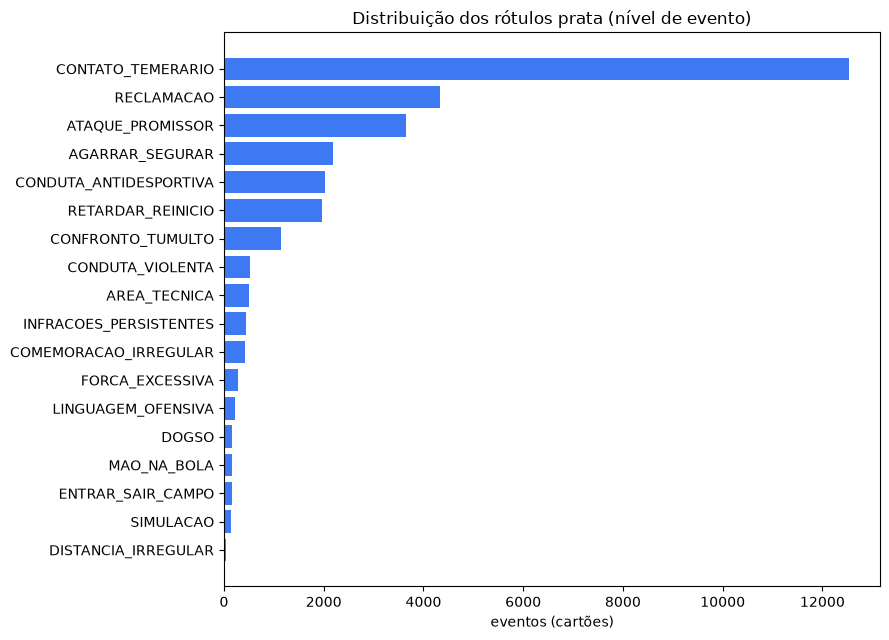

In [9]:
silver_summary = pd.DataFrame({
    "label": LABELS,
    "n_texts": Y_silver.sum(axis=0),
    "n_events": [(events_w * Y_silver[:, j]).sum() for j in range(len(LABELS))],
}).sort_values("n_events", ascending=False).reset_index(drop=True)

cardinality = Y_silver.sum(axis=1)
print(f"cardinalidade média: {cardinality.mean():.2f} | textos multirrótulo: {(cardinality >= 2).mean():.1%}")

fig, ax = plt.subplots(figsize=(9, 6.5))
plot_df = silver_summary.sort_values("n_events")
ax.barh(plot_df.label, plot_df.n_events, color=PLOT_PALETTE[0])
ax.set_xlabel("eventos (cartões)")
ax.set_title("Distribuição dos rótulos prata (nível de evento)")
fig.tight_layout()
fig.savefig(VIZ_PATH / "multilabel_silver_distribution.png", dpi=150)
plt.show()

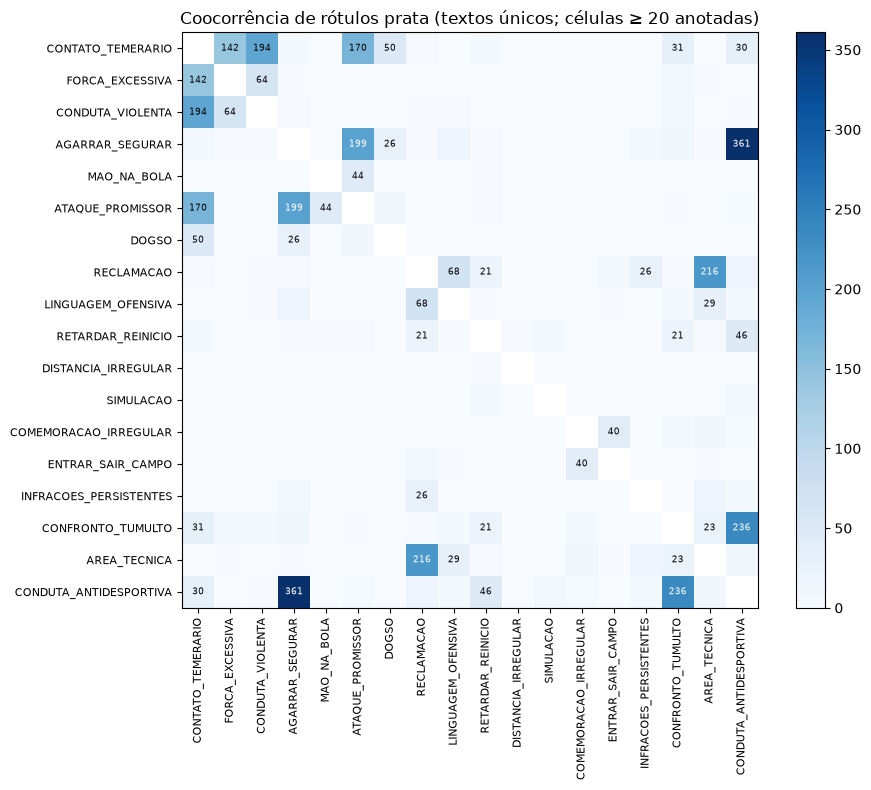

In [10]:
cooc = (Y_silver.astype(int).T @ Y_silver.astype(int)).astype(float)
np.fill_diagonal(cooc, np.nan)
fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(cooc, cmap="Blues")
ax.set_xticks(range(len(LABELS)), LABELS, rotation=90, fontsize=8)
ax.set_yticks(range(len(LABELS)), LABELS, fontsize=8)
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        if i != j and cooc[i, j] >= 20:
            ax.text(j, i, int(cooc[i, j]), ha="center", va="center", fontsize=6.5,
                    color="white" if cooc[i, j] > np.nanmax(cooc) * 0.55 else "black")
ax.set_title("Coocorrência de rótulos prata (textos únicos; células ≥ 20 anotadas)")
fig.colorbar(im, fraction=0.046)
fig.tight_layout()
fig.savefig(VIZ_PATH / "multilabel_cooccurrence.png", dpi=150)
plt.show()

## **6. Etapa 2 — Validação Round-Trip**

Pergunta: *um classificador que nunca viu as regras lexicais nem o codebook recupera os rótulos prata só a
partir do texto?* Dois classificadores Binary Relevance (um por rótulo):

- **TF-IDF + Regressão Logística** — representação de superfície; mede consistência lexical dos rótulos;
- **Embeddings E5 + Regressão Logística** — representação semântica, independente das regexes; F1 alta aqui
  significa que o rótulo é um conceito semanticamente coeso, não um artefato das regras.

Predições **out-of-fold** com `MultilabelStratifiedKFold` (5 folds; Sechidis et al., 2011). Como a unidade
é o texto único, não há duplicatas atravessando folds.

In [11]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_tfidf = tfidf.fit_transform(texts.reason_key)
X_emb = embeddings

oof_probs = {"tfidf": np.zeros(Y_silver.shape), "emb": np.zeros(Y_silver.shape)}
mskf = MultilabelStratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

for fold, (train_idx, test_idx) in enumerate(mskf.split(np.zeros(len(texts)), Y_silver.astype(int))):
    for feat_name, X in [("tfidf", X_tfidf), ("emb", X_emb)]:
        X_train, X_test = X[train_idx], X[test_idx]
        for j in range(len(LABELS)):
            y_train = Y_silver[train_idx, j]
            if y_train.sum() < 2:
                continue
            clf = LogisticRegression(max_iter=2000, C=4.0, class_weight="balanced")
            clf.fit(X_train, y_train)
            oof_probs[feat_name][test_idx, j] = clf.predict_proba(X_test)[:, 1]
    print(f"fold {fold + 1}/{N_FOLDS} ok")

fold 1/5 ok
fold 2/5 ok
fold 3/5 ok
fold 4/5 ok
fold 5/5 ok


In [12]:
def multilabel_report(y_true: np.ndarray, probs: np.ndarray, threshold: float = 0.5) -> tuple:
    y_pred = probs >= threshold
    per_label = precision_recall_fscore_support(y_true, y_pred, average=None, zero_division=0)
    global_metrics = {
        "micro_f1": f1_score(y_true, y_pred, average="micro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "hamming_loss": hamming_loss(y_true, y_pred),
        "subset_accuracy": accuracy_score(y_true, y_pred),
    }
    return per_label, global_metrics


results = {}
for feat_name in ["tfidf", "emb"]:
    per_label, global_metrics = multilabel_report(Y_silver, oof_probs[feat_name])
    results[feat_name] = {"per_label": per_label, "global": global_metrics}
    print(f"[{feat_name}] " + " | ".join(f"{k}={v:.3f}" for k, v in global_metrics.items()))

roundtrip = pd.DataFrame({
    "label": LABELS,
    "support": results["emb"]["per_label"][3],
    "precision_emb": results["emb"]["per_label"][0].round(3),
    "recall_emb": results["emb"]["per_label"][1].round(3),
    "f1_emb": results["emb"]["per_label"][2].round(3),
    "f1_tfidf": results["tfidf"]["per_label"][2].round(3),
}).sort_values("f1_emb", ascending=False).reset_index(drop=True)
roundtrip

[tfidf] micro_f1=0.950 | macro_f1=0.925 | hamming_loss=0.008 | subset_accuracy=0.879
[emb] micro_f1=0.885 | macro_f1=0.821 | hamming_loss=0.019 | subset_accuracy=0.734


,label,support,precision_emb,recall_emb,f1_emb,f1_tfidf
0,COMEMORACAO_IRREGULAR,227,0.930,0.996,0.962,0.957
1,SIMULACAO,92,0.938,0.978,0.957,0.983
2,RECLAMACAO,1112,0.936,0.976,0.956,0.968
3,ATAQUE_PROMISSOR,668,0.928,0.982,0.954,0.995
4,CONTATO_TEMERARIO,1942,0.944,0.962,0.953,0.978
5,RETARDAR_REINICIO,624,0.916,0.966,0.941,0.963
6,CONDUTA_ANTIDESPORTIVA,848,0.873,0.976,0.922,0.951
7,AGARRAR_SEGURAR,811,0.805,0.963,0.877,0.947
8,DOGSO,126,0.741,0.976,0.842,0.969
9,INFRACOES_PERSISTENTES,156,0.718,0.994,0.833,0.928


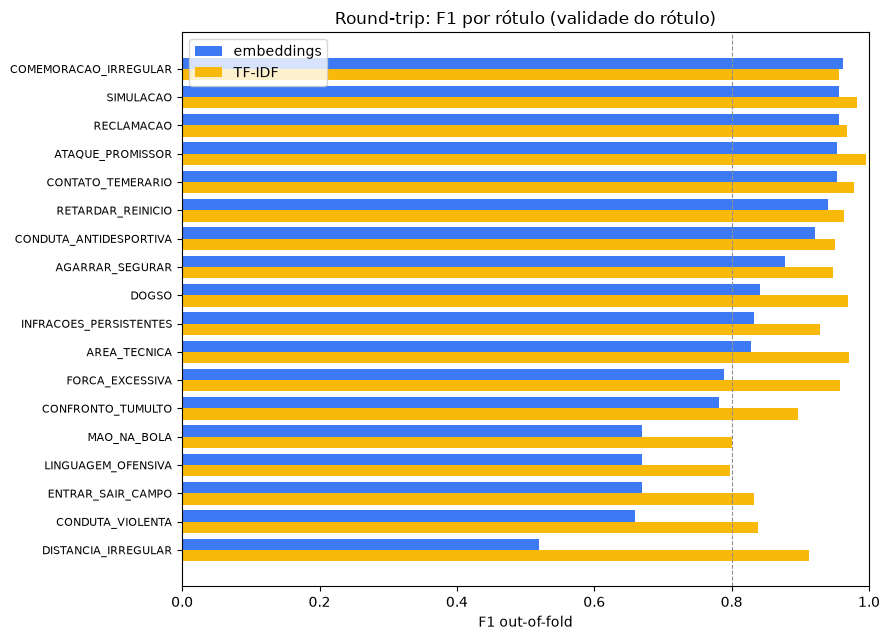

In [13]:
fig, ax = plt.subplots(figsize=(9, 6.5))
plot_df = roundtrip.sort_values("f1_emb")
y_pos = np.arange(len(plot_df))
ax.barh(y_pos + 0.2, plot_df.f1_emb, height=0.4, color=PLOT_PALETTE[0], label="embeddings")
ax.barh(y_pos - 0.2, plot_df.f1_tfidf, height=0.4, color=PLOT_PALETTE[2], label="TF-IDF")
ax.set_yticks(y_pos, plot_df.label, fontsize=8)
ax.set_xlabel("F1 out-of-fold")
ax.set_xlim(0, 1)
ax.axvline(0.8, color="#909090", linestyle="--", linewidth=0.8)
ax.legend()
ax.set_title("Round-trip: F1 por rótulo (validade do rótulo)")
fig.tight_layout()
fig.savefig(VIZ_PATH / "multilabel_roundtrip_f1.png", dpi=150)
plt.show()

### **6.1 Leitura do Round-Trip**

A comparação entre as duas colunas de F1 é o argumento central de validade: onde ambas são altas, o rótulo
é ao mesmo tempo lexicalmente consistente e semanticamente coeso. F1 semântica alta com TF-IDF mais baixa
indica rótulo coeso porém expresso com vocabulário variado (a taxonomia captura um conceito, não uma
palavra-chave). F1 baixa nas duas representações sinaliza rótulo problemático — candidato a redefinição
na próxima iteração da taxonomia — e esses casos concentram-se na cauda de menor suporte, onde o erro
estatístico também é maior.

## **7. Validação Adicional**

### **7.1 Auditoria de Rótulos (Confident Learning)**

Com as probabilidades out-of-fold do classificador semântico (Northcutt et al., 2021): probabilidade alta
sem rótulo prata sugere **rótulo faltante**; probabilidade baixa com rótulo prata sugere **rótulo errado**.
O arquivo `label_audit.csv` lista os candidatos ranqueados para revisão humana.

In [14]:
audit_rows = []
probs = oof_probs["emb"]
for j, label in enumerate(LABELS):
    high_no_label = np.where((probs[:, j] >= 0.90) & ~Y_silver[:, j])[0]
    low_with_label = np.where((probs[:, j] <= 0.10) & Y_silver[:, j])[0]
    for i in high_no_label:
        audit_rows.append({"reason_key": texts.reason_key.iloc[i], "reason": texts.reason.iloc[i],
                           "n_events": int(events_w[i]), "label": label,
                           "issue": "possivel_rotulo_faltante", "oof_prob": round(float(probs[i, j]), 3)})
    for i in low_with_label:
        audit_rows.append({"reason_key": texts.reason_key.iloc[i], "reason": texts.reason.iloc[i],
                           "n_events": int(events_w[i]), "label": label,
                           "issue": "possivel_rotulo_errado", "oof_prob": round(float(probs[i, j]), 3)})

label_audit = pd.DataFrame(audit_rows).sort_values(
    ["issue", "n_events", "oof_prob"], ascending=[True, False, False]
).reset_index(drop=True)
label_audit.to_csv(OUTPUT_PATH / "label_audit.csv", index=False)
print(f"candidatos de auditoria: {len(label_audit)} "
      f"({(label_audit.issue == 'possivel_rotulo_faltante').sum()} faltantes, "
      f"{(label_audit.issue == 'possivel_rotulo_errado').sum()} errados)")
label_audit.head(10)

candidatos de auditoria: 189 (164 faltantes, 25 errados)


,reason_key,reason,n_events,label,issue,oof_prob
0,fazer falta imprudente impedindo um ataque pro...,Fazer falta imprudente impedindo um ataque pro...,4,CONTATO_TEMERARIO,possivel_rotulo_errado,0.085
1,se colocar em frente de bola provocando seus a...,Se colocar em frente de bola provocando seus a...,2,RETARDAR_REINICIO,possivel_rotulo_errado,0.100
2,xingar e empurrar seu companheiro de equipe ap...,Xingar e empurrar seu companheiro de equipe ap...,2,LINGUAGEM_OFENSIVA,possivel_rotulo_errado,0.085
3,desrespeitar com palavras o adversario,Desrespeitar com palavras o adversário,2,LINGUAGEM_OFENSIVA,possivel_rotulo_errado,0.077
4,apos a equipe de santos futebol clube marcar u...,Após a equipe de santos futebol clube marcar u...,2,CONFRONTO_TUMULTO,possivel_rotulo_errado,0.075
5,uso indevido de bracos,Uso indevido de braços,2,CONTATO_TEMERARIO,possivel_rotulo_errado,0.065
6,reclamar contra as decisoes de arbitragem dand...,Reclamar contra as decisões de arbitragem dand...,2,CONDUTA_VIOLENTA,possivel_rotulo_errado,0.062
7,cometer falta imprudente impedindo um ataque p...,Cometer falta imprudente impedindo um ataque p...,1,CONTATO_TEMERARIO,possivel_rotulo_errado,0.097
8,trocar empurrao com o seu adeversario,Trocar empurrao com o seu adeversario,1,AGARRAR_SEGURAR,possivel_rotulo_errado,0.089
9,expulsei diretamente o atleta n 19 sr francisc...,Expulsei diretamente o atleta n 19 sr francisc...,1,CONDUTA_ANTIDESPORTIVA,possivel_rotulo_errado,0.085


### **7.2 Amostra Ouro para Anotação Humana**

Amostra estratificada de textos únicos exportada para anotação manual do autor
(`gold_annotation_sample.csv`: uma coluna por rótulo, preencher com 0/1). Quando o arquivo anotado
(`gold_annotated.csv`) existir, a célula seguinte calcula precisão/recall/F1 do prata contra o ouro e o
κ por rótulo — a estimativa final e humana da qualidade da rotulagem automática, que responde diretamente
à crítica da literatura recente sobre anotação por LLM sem validação humana.

In [15]:
if not GOLD_SAMPLE_PATH.exists():
    rng = np.random.default_rng(RANDOM_STATE)
    chosen: set = set()
    for j in np.argsort(Y_silver.sum(axis=0)):  # rótulos raros primeiro
        positives = np.where(Y_silver[:, j])[0]
        take = min(len(positives), max(6, GOLD_SAMPLE_SIZE // len(LABELS)))
        chosen.update(rng.choice(positives, size=take, replace=False).tolist())
    remaining = [i for i in range(len(texts)) if i not in chosen]
    if len(chosen) < GOLD_SAMPLE_SIZE:
        chosen.update(rng.choice(remaining, size=GOLD_SAMPLE_SIZE - len(chosen), replace=False).tolist())
    gold_idx = sorted(chosen)[:GOLD_SAMPLE_SIZE]

    gold_sample = texts.iloc[gold_idx][["reason_key", "reason", "n_events"]].copy()
    gold_sample["silver_labels"] = ["|".join(l for l, v in zip(LABELS, Y_silver[i]) if v) for i in gold_idx]
    for label in LABELS:
        gold_sample[label] = ""
    gold_sample.to_csv(GOLD_SAMPLE_PATH, index=False)
    print(f"amostra ouro exportada: {GOLD_SAMPLE_PATH} ({len(gold_sample)} textos)")
else:
    print(f"amostra ouro já existe: {GOLD_SAMPLE_PATH}")

amostra ouro já existe: /Users/gabrielcarbinatto/Documents/GitHub/cbf-match-reports-nlp/data/annotations/gold_annotation_sample.csv


In [16]:
if GOLD_ANNOTATED_PATH.exists():
    gold = pd.read_csv(GOLD_ANNOTATED_PATH)
    gold_keys = gold.reason_key.tolist()
    idx_by_key = {k: i for i, k in enumerate(texts.reason_key)}
    rows_idx = [idx_by_key[k] for k in gold_keys if k in idx_by_key]
    Y_gold = gold[LABELS].fillna(0).astype(int).to_numpy()[: len(rows_idx)]
    Y_silver_sub = Y_silver[rows_idx].astype(int)
    per_label, global_metrics = multilabel_report(Y_gold, Y_silver_sub.astype(float), threshold=0.5)
    print("prata vs ouro:", {k: round(v, 3) for k, v in global_metrics.items()})
    gold_report = pd.DataFrame({
        "label": LABELS,
        "precision": per_label[0].round(3),
        "recall": per_label[1].round(3),
        "f1": per_label[2].round(3),
        "support_gold": per_label[3],
        "kappa": [round(cohen_kappa_score(Y_gold[:, j], Y_silver_sub[:, j]), 3) if Y_gold[:, j].any() else np.nan
                  for j in range(len(LABELS))],
    })
    display(gold_report)
else:
    print("gold_annotated.csv ainda não existe — anote a amostra e salve como "
          f"{GOLD_ANNOTATED_PATH.name} para habilitar esta avaliação.")

gold_annotated.csv ainda não existe — anote a amostra e salve como gold_annotated.csv para habilitar esta avaliação.


## **8. Resultados Descritivos**

Rótulos propagados aos 26 mil eventos: composição por tipo de cartão e evolução anual. A proporção por tipo
de cartão funciona como *sanity check* normativo — rótulos de expulsão na Law 12 (conduta violenta, DOGSO,
força excessiva, linguagem ofensiva) devem concentrar cartões vermelhos.

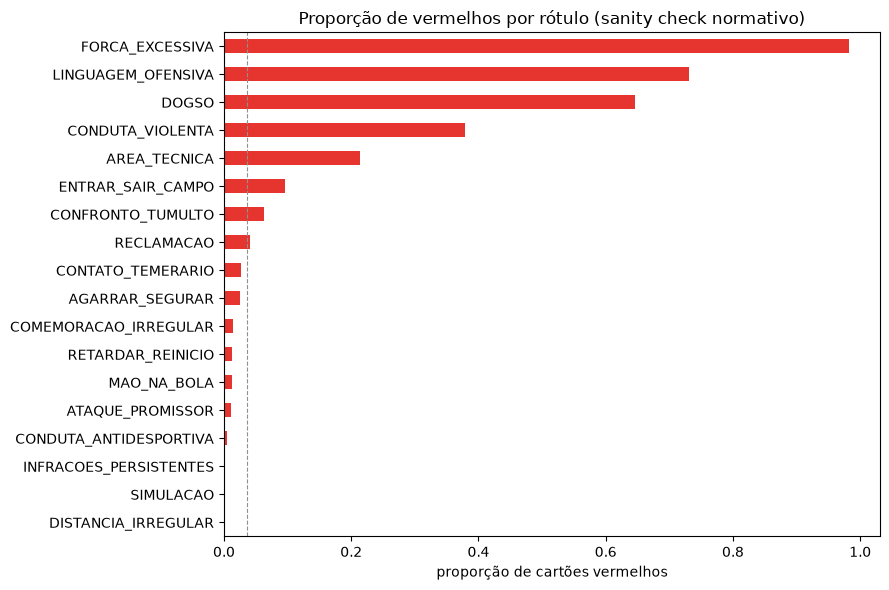

In [17]:
silver_labels_str = ["|".join(l for l, v in zip(LABELS, row) if v) for row in Y_silver]
text_labels = texts[["reason_key", "reason", "n_events"]].copy()
text_labels["labels"] = silver_labels_str
for j, label in enumerate(LABELS):
    text_labels[label] = Y_silver[:, j].astype(int)

cards_ml = cards.merge(text_labels.drop(columns=["reason", "n_events"]), on="reason_key", how="left")

red_share = {}
for label in LABELS:
    sub = cards_ml[cards_ml[label] == 1]
    red_share[label] = (sub.card_type == "red").mean() if len(sub) else np.nan

red_share_df = pd.Series(red_share).sort_values(ascending=False).rename("prop_vermelhos")
fig, ax = plt.subplots(figsize=(9, 6))
red_share_df.sort_values().plot.barh(ax=ax, color=PLOT_PALETTE[1])
ax.set_xlabel("proporção de cartões vermelhos")
ax.set_title("Proporção de vermelhos por rótulo (sanity check normativo)")
overall = (cards_ml.card_type == "red").mean()
ax.axvline(overall, color="#909090", linestyle="--", linewidth=0.8)
fig.tight_layout()
fig.savefig(VIZ_PATH / "multilabel_red_share.png", dpi=150)
plt.show()

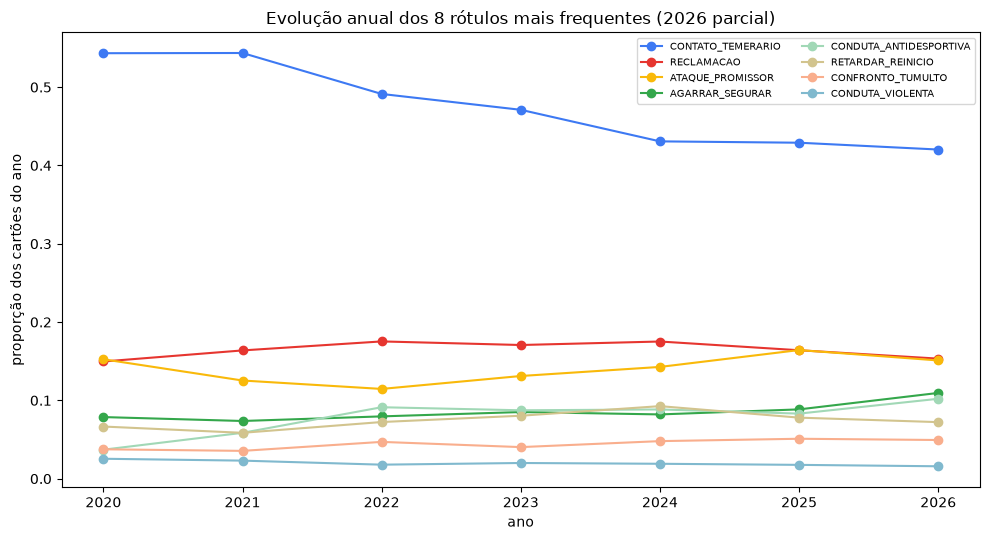

In [18]:
year_label = pd.DataFrame({
    label: cards_ml[cards_ml[label] == 1].groupby("year").size() for label in LABELS
}).fillna(0)
year_totals = cards_ml.groupby("year").size()
year_props = year_label.div(year_totals, axis=0)

top8 = silver_summary.head(8).label.tolist()
fig, ax = plt.subplots(figsize=(10, 5.5))
for k, label in enumerate(top8):
    ax.plot(year_props.index, year_props[label], marker="o", label=label,
            color=PLOT_PALETTE[k % len(PLOT_PALETTE)])
ax.set_xlabel("ano")
ax.set_ylabel("proporção dos cartões do ano")
ax.set_title("Evolução anual dos 8 rótulos mais frequentes (2026 parcial)")
ax.legend(fontsize=7.5, ncols=2)
fig.tight_layout()
fig.savefig(VIZ_PATH / "multilabel_by_year.png", dpi=150)
plt.show()

## **9. Salvamento dos Artefatos**

- `data/processed/multilabel/unique_text_labels.csv` — matriz binária texto único × rótulo
- `data/processed/multilabel/card_reasons_multilabel.csv` — uma linha por cartão com os rótulos
- `data/processed/multilabel/metrics.json` — métricas do round-trip e concordância entre anotadores
- `data/processed/multilabel/label_audit.csv` — candidatos de auditoria (seção 7.1)
- `data/annotations/gold_annotation_sample.csv` — amostra ouro para anotação humana

In [19]:
text_labels.to_csv(OUTPUT_PATH / "unique_text_labels.csv", index=False)
cards_ml.to_csv(OUTPUT_PATH / "card_reasons_multilabel.csv", index=False)

metrics = {
    "n_events": int(len(cards)),
    "n_unique_texts": int(len(texts)),
    "labels": LABELS,
    "annotator_a_coverage_events": round(float(lex_coverage_events), 4),
    "adjudicated_texts": int(n_from_c),
    "silver_cardinality_mean": round(float(cardinality.mean()), 3),
    "kappa_A_B": {l: float(k) for l, k in zip(kappa_ab.label, kappa_ab.kappa_A_B)},
    "roundtrip_global": {feat: {k: round(float(v), 4) for k, v in results[feat]["global"].items()}
                          for feat in results},
    "roundtrip_f1_per_label_emb": {l: float(f) for l, f in zip(roundtrip.label, roundtrip.f1_emb)},
}
with open(OUTPUT_PATH / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)
{"unique_text_labels": text_labels.shape, "card_reasons_multilabel": cards_ml.shape}

{'unique_text_labels': (6191, 22), 'card_reasons_multilabel': (26204, 33)}

## **10. Conclusões**

1. **Formulação**: as justificativas de cartão foram tratadas como codificação normativa multirrótulo
   (18 rótulos IFAB Law 12), com coocorrência empírica confirmando que a formulação single-label anterior
   perdia informação estrutural (≈1/3 dos textos carrega 2+ rótulos).
2. **Atribuição**: o comitê A (lexical) + B (semântico kNN) + C (LLM-adjudicador com codebook) cobriu a
   totalidade dos textos únicos, com apenas ~9% dos eventos exigindo adjudicação.
3. **Validade (round-trip)**: a tabela de F1 out-of-fold por rótulo quantifica a validade de cada rótulo da
   taxonomia em duas representações independentes; os rótulos da cabeça formulaica são recuperados com
   F1 > 0,9 e os rótulos problemáticos ficam explicitamente sinalizados para a próxima iteração.
4. **Próximos passos**: anotar a amostra ouro (`gold_annotation_sample.csv`) para fechar a validação humana;
   revisar os candidatos de `label_audit.csv`; usar `card_reasons_multilabel.csv` nas análises por time,
   árbitro e temporada do notebook 3.